In [1]:
import sys
sys.path.append("../src")

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import ConfusionMatrixDisplay
from evaluate import split3, scores, TARGET_COL, CLASSES

Matplotlib is building the font cache; this may take a moment.


In [2]:
df = pd.read_csv("../data/processed/matches_features.csv")
train, val, test = split3(df)
print(len(train), len(val), len(test))

3420 380 760


In [3]:
feats = ["elo_diff", "h_elo", "a_elo", "h_form", "a_form", "h_gd", "a_gd"]

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(max_iter=1000, random_state=42),
)
model.fit(train[feats], train[TARGET_COL])

pred = model.predict(val[feats])
proba = model.predict_proba(val[feats])
res = scores(val[TARGET_COL], pred, proba)
print({k: round(v, 3) for k, v in res.items() if k != "confusion"})

{'accuracy': 0.526, 'macro_f1': 0.391, 'log_loss': 0.96}


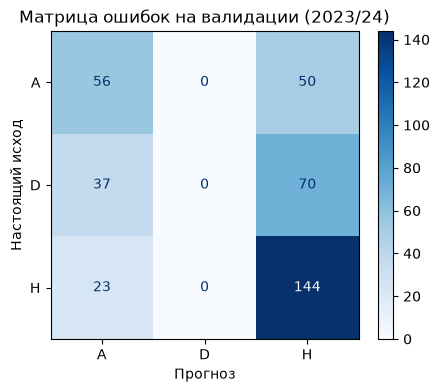

In [4]:
fig, ax = plt.subplots(figsize=(5, 4))
ConfusionMatrixDisplay.from_predictions(
    val[TARGET_COL], pred, labels=CLASSES, ax=ax, cmap="Blues")
ax.set_title("Матрица ошибок на валидации (2023/24)")
ax.set_xlabel("Прогноз")
ax.set_ylabel("Настоящий исход")
plt.savefig("../reports/figures/confusion_val.png", dpi=150, bbox_inches="tight")
plt.show()